# Question 2 : Faster RCNN Based Model Object Detection


## Task :

<ul>
<li>Train model Faster RCNN for object detection in dataset Pascal VOC </li>
</ul>


## Model Description

**Convolutional Layer:**
Convolutional layers are fundamental building blocks in convolutional neural networks (CNNs). They perform convolutions on input images using learnable filters (kernels), which helps in capturing hierarchical features of the input data. In Faster R-CNN, convolutional layers are used to extract feature maps from the input images.

**RPN (Region Proposal Network):**
The RPN is a part of the Faster R-CNN architecture responsible for proposing candidate object regions within the feature map generated by the convolutional layers. It operates by sliding a small network (often a few convolutional layers) over the feature map, predicting whether there is an object or not, and suggesting bounding box proposals.

**ROI (Region of Interest) Pooling:**
After obtaining region proposals from the RPN, the ROI pooling layer is used to extract fixed-size feature maps from each proposed region. Since the proposed regions may have different sizes, ROI pooling ensures that they are all resized to a consistent size. This is important for feeding the proposals into subsequent layers for further processing.

**Classification Layer:**
The classification layer is responsible for classifying the content within each region proposal. In Faster R-CNN, it typically involves two sub-tasks: object classification (determining the class of the object within the proposal) and bounding box regression (refining the coordinates of the bounding box). This layer is often connected to the ROI-pooled feature maps and produces final class scores and bounding box coordinates for each proposed region.

## Import Libraries

In [ ]:
from torch.utils.data import DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn
import math
import sys
import time
import torch
import os
from scipy.io import loadmat
from google.colab import drive
import random
import matplotlib.pyplot as plt
from PIL import Image
import xml.etree.ElementTree as ET
import torchvision.models as models
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import warnings

warnings.filterwarnings('ignore')

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
gpu = True

if gpu == True:
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

Gathering dataset folder

In [ ]:
source_path = '/content/drive/MyDrive/Wildfire Smoke.v1-raw.voc/'
destination_path = '/content/dataset'
!cp -r "$source_path" "$destination_path"


## Preprocess

Show Images ( 5 random selected ) + labels

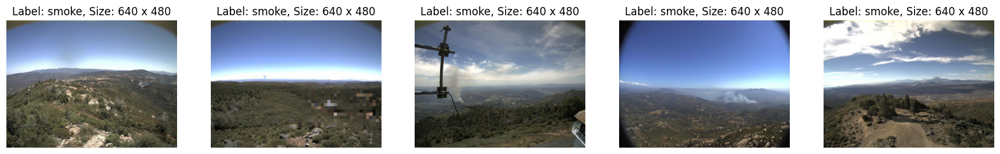

In [ ]:


# Paths
xml_folder = '/content/dataset/train'
image_folder = '/content/dataset/train'


def extract_info(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    label = root.find('.//name').text

    size_elem = root.find('.//size')
    width = int(size_elem.find('width').text)
    height = int(size_elem.find('height').text)

    return label, width, height

xml_files = [f for f in os.listdir(xml_folder) if f.endswith('.xml')]

import random
random.seed(42)
selected_files = random.sample(xml_files, 5)

plt.figure(figsize=(20, 3))

for i, xml_file in enumerate(selected_files):
    xml_path = os.path.join(xml_folder, xml_file)

    label, width, height = extract_info(xml_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(Image.open(os.path.join(image_folder, xml_file.replace('.xml', '.jpg'))))
    plt.title(f"Label: {label}, Size: {width} x {height}")
    plt.axis('off')

plt.show()


get number of classes

In [ ]:
def extract_labels(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    # Extract label
    label = root.find('.//name').text
    return label

In [ ]:
xml_files = [f for f in os.listdir(xml_folder) if f.endswith('.xml')]
unique_labels = set()

for xml_file in xml_files:
    xml_path = os.path.join(xml_folder, xml_file)

    # Extract label
    label = extract_labels(xml_path)

    # Add label to set
    unique_labels.add(label)

# Number of unique labels
num_unique_labels = len(unique_labels)

print(f"Number of unique labels: {num_unique_labels}")
print("Unique Labels:", unique_labels)

Number of unique labels: 1
Unique Labels: {'smoke'}


resize images

In [ ]:
# desired_size = (224, 224)


In [ ]:
folders = ['/content/dataset/train', '/content/dataset/valid', '/content/dataset/test']


In [ ]:
# def custom_round(number):
#     integer_part = int(number)
#     fraction_part = number - integer_part

#     if fraction_part > 0.5:
#         return integer_part + 1
#     else:
#         return integer_part

# def resize_bounding_box(original_width, original_height, xmin, xmax, ymin, ymax, target_width, target_height):
#     resize_factor_x = target_width / original_width
#     resize_factor_y = target_height / original_height

#     resized_xmin = custom_round(xmin * resize_factor_x)
#     resized_xmax = custom_round(xmax * resize_factor_x)
#     resized_ymin = custom_round(ymin * resize_factor_y)
#     resized_ymax = custom_round(ymax * resize_factor_y)

#     return resized_xmin, resized_xmax, resized_ymin, resized_ymax


In [ ]:
# def resize_image_and_xml(image_path, xml_path):
#     img = Image.open(image_path)
#     img = img.resize(desired_size)

#     tree = ET.parse(xml_path)
#     root = tree.getroot()

#     size_elem = root.find('.//size')

#     xmin = int(root.find('.//xmin').text)
#     xmax = int(root.find('.//xmax').text)
#     ymin = int(root.find('.//ymin').text)
#     ymax = int(root.find('.//ymax').text)
#     width = int(root.find('.//width').text)
#     height = int(root.find('.//height').text)

#     resized_xmin, resized_xmax, resized_ymin, resized_ymax = resize_bounding_box(
#       original_width=width,
#       original_height=height,
#       xmin=xmin,
#       xmax=xmax,
#       ymin=ymin,
#       ymax=ymax,
#       target_width=244,
#       target_height=244
#     )

#     root.find('.//xmin').text = str(resized_xmin)
#     root.find('.//xmax').text = str(resized_xmax)
#     root.find('.//ymin').text = str(resized_ymin)
#     root.find('.//ymax').text = str(resized_ymax)
#     size_elem.find('width').text = str(desired_size[0])
#     size_elem.find('height').text = str(desired_size[1])

#     tree.write(xml_path)

#     img.save(image_path)

In [ ]:
# for folder in folders:
#     # Get list of image files
#     image_files = [f for f in os.listdir(folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

#     # Loop through each image file
#     for image_file in image_files:
#         image_path = os.path.join(folder, image_file)
#         xml_path = os.path.join(folder, image_file.replace('.jpg', '.xml').replace('.jpeg', '.xml').replace('.png', '.xml'))

#         # Resize image and update XML
#         resize_image_and_xml(image_path, xml_path)

# print("Images and XML files have been resized and updated.")

## Prepare the data

In [ ]:
import torch
from torch.utils.data import Dataset
import cv2
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader


In [ ]:
class_mapping = {'smoke': 1}

In [ ]:

class WildFireSmoke_Dataset(Dataset):
    def __init__(self, image_path, categories, transforms=None):
        self.image_path = image_path
        self.categories = categories
        self.transforms = transforms
        self.df = self.load_data()
        self.images = self.df['filename'].unique()

        # Extract unique labels from the dataset
        xml_files = [f for f in os.listdir(self.image_path) if f.endswith('.xml')]
        unique_labels = set()

        for xml_file in xml_files:
            xml_path = os.path.join(self.image_path, xml_file)
            label = extract_labels(xml_path)
            unique_labels.add(label)

        self.unique_labels = list(unique_labels)

    def load_data(self):
        data  = {'filename': [], 'width': [], 'height': [], 'xmin': [], 'ymin': [], 'xmax': [], 'ymax': [], 'class': []}
        xml_files = [f for f in os.listdir(self.image_path) if f.endswith('.xml')]
        xml_files = [f for f in os.listdir(self.image_path) if f.endswith('.xml')]

        for xml_file in xml_files:
            xml_path = os.path.join(self.image_path, xml_file)
            tree = ET.parse(xml_path)
            root = tree.getroot()

            filename = root.find('.//filename').text
            width = int(root.find('.//width').text)
            height = int(root.find('.//height').text)

            for obj in root.findall('.//object'):
                class_name = obj.find('.//name').text
                bbox = obj.find('.//bndbox')
                xmin = int(bbox.find('.//xmin').text)
                ymin = int(bbox.find('.//ymin').text)
                xmax = int(bbox.find('.//xmax').text)
                ymax = int(bbox.find('.//ymax').text)

                data['filename'].append(filename)
                data['width'].append(width)
                data['height'].append(height)
                data['xmin'].append(xmin)
                data['ymin'].append(ymin)
                data['xmax'].append(xmax)
                data['ymax'].append(ymax)
                data['class'].append(1)

        df = pd.DataFrame(data)
        return df

        pass

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        image_file = os.path.join(self.image_path,self.df.iloc[idx]['filename'])
        img = cv2.imread(image_file)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = img.astype(np.float32) / 255.0

        image_data = self.df[self.df['filename'] == self.df.iloc[idx]['filename']]
        xmins = image_data['xmin'].values
        ymins = image_data['ymin'].values
        xmaxs = image_data['xmax'].values
        ymaxs = image_data['ymax'].values

        boxes = torch.as_tensor(np.stack([xmins, ymins, xmaxs, ymaxs], axis=1), dtype=torch.float32)
        labels = torch.as_tensor(image_data['class'].values, dtype=torch.int64)
        image_id = torch.tensor([idx])
        areas = (boxes[:,3] - boxes[:,1]) * (boxes[:,2] - boxes[:,0])
        areas = torch.as_tensor(areas, dtype=torch.float32)
        iscrowd = torch.zeros((len(labels),), dtype=torch.int64)

        target = {}
        target['boxes']    = boxes
        target['labels']   = labels
        target['image_id'] = image_id
        target['area']     = areas
        target['iscrowd']  = iscrowd

        if self.transforms is not None:                                                                      #
                                                                                                             #
            # Define transformation                                                                          #
            transformed = self.transforms(image=img, bboxes=boxes, labels=labels)                            #
                                                                                                             #
            # Image transformation                                                                           #
            img = transformed['image']                                                                       #
                                                                                                             #
            # Target transformation                                                                          #
            target['boxes'] = torch.as_tensor(transformed['bboxes'], dtype=torch.float32)

        return torch.as_tensor(img, dtype=torch.float32), target

    def get_height_and_width(self, image):
        image_data = self.df.loc[self.df['filename'] == image]
        return image_data['width'].values[0], image_data['height'].values[0]


In [ ]:
# Train set transformations
import albumentations as A
from albumentations.pytorch.transforms import ToTensorV2
transform_train = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.2),
    ToTensorV2(p=1)], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels']))

# Validation set transformations
transform_valid = A.Compose([
    ToTensorV2(p=1)], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels']))

In [ ]:
def collate_fn(batch):
    return tuple(zip(*batch))

In [ ]:
train_path = '/content/dataset/train'
valid_path = '/content/dataset/valid'

In [ ]:
train_dataset = WildFireSmoke_Dataset(image_path=train_path, categories=['smoke'], transforms=transform_train)
valid_dataset = WildFireSmoke_Dataset(image_path=valid_path, categories=['smoke'], transforms=transform_valid)

# train_loader = DataLoader(train_dataset, batch_size=4, num_workers = 2,shuffle=True)
# valid_loader = DataLoader(train_dataset, batch_size=4,num_workers = 2, shuffle=False)

data_loader_train = torch.utils.data.DataLoader(
        train_dataset,
        batch_size  = 4,
        shuffle     = True,
        num_workers = 2,
        collate_fn  = collate_fn)

data_loader_valid = torch.utils.data.DataLoader(
        valid_dataset,
        batch_size  = 4,
        shuffle     = False,
        num_workers = 2,
        collate_fn  = collate_fn)

In [ ]:
print(f"Length of train dataset: {len(train_dataset)}")
print(f"Length of valid dataset: {len(valid_dataset)}")

Length of train dataset: 516
Length of valid dataset: 147


In [ ]:
train_dataset.df

,filename,width,height,xmin,ymin,xmax,ymax,class
0,ck0u01dbyuoe30701p6pfzb0q_jpeg.rf.dc34aba65774...,640,480,159,167,422,321,1
1,ck0kdox8w69td0838i6leuzy9_jpeg.rf.333d536f32a8...,640,480,124,215,191,314,1
2,ck0t4sh7pnk3v09447wbxifkk_jpeg.rf.d723fb8fb9b1...,640,480,445,228,583,254,1
3,ck0qb9do2fwc708385reizk6h_jpeg.rf.8353ce140548...,640,480,185,260,223,291,1
4,ck0kkg0u65u3q0863z6w2psqp_jpeg.rf.80b296c2869e...,640,480,468,193,541,245,1
...,...,...,...,...,...,...,...,...
511,ck0kfk23ukj1m0848e93um98b_jpeg.rf.457fd102e55b...,640,480,308,147,560,255,1
512,ck0tsyvp361ow084867dinue0_jpeg.rf.d47c7f4008f3...,640,480,499,246,637,288,1
513,ck0kkg80v5x900794hcgsb4e1_jpeg.rf.c14e4f981367...,640,480,121,202,194,313,1
514,ck0ndbtmr8oa50721hzgxpue8_jpeg.rf.98eed4485749...,640,480,310,159,443,252,1


In [ ]:
# train_dataset.df['class'] = train_dataset.df['class'].map(class_mapping)
# valid_dataset.df['class'] = valid_dataset.df['class'].map(class_mapping)

In [ ]:
train_dataset.df

,filename,width,height,xmin,ymin,xmax,ymax,class
0,ck0u01dbyuoe30701p6pfzb0q_jpeg.rf.dc34aba65774...,640,480,159,167,422,321,1
1,ck0kdox8w69td0838i6leuzy9_jpeg.rf.333d536f32a8...,640,480,124,215,191,314,1
2,ck0t4sh7pnk3v09447wbxifkk_jpeg.rf.d723fb8fb9b1...,640,480,445,228,583,254,1
3,ck0qb9do2fwc708385reizk6h_jpeg.rf.8353ce140548...,640,480,185,260,223,291,1
4,ck0kkg0u65u3q0863z6w2psqp_jpeg.rf.80b296c2869e...,640,480,468,193,541,245,1
...,...,...,...,...,...,...,...,...
511,ck0kfk23ukj1m0848e93um98b_jpeg.rf.457fd102e55b...,640,480,308,147,560,255,1
512,ck0tsyvp361ow084867dinue0_jpeg.rf.d47c7f4008f3...,640,480,499,246,637,288,1
513,ck0kkg80v5x900794hcgsb4e1_jpeg.rf.c14e4f981367...,640,480,121,202,194,313,1
514,ck0ndbtmr8oa50721hzgxpue8_jpeg.rf.98eed4485749...,640,480,310,159,443,252,1


showing a sample from dataset train to check if everything is fine

In [ ]:
train_dataset[1]

(tensor([[[0.1961, 0.1961, 0.1961,  ..., 0.3922, 0.2000, 0.2314],
          [0.1961, 0.1961, 0.1961,  ..., 0.4039, 0.4549, 0.3098],
          [0.1961, 0.1961, 0.1961,  ..., 0.1098, 0.3216, 0.2392],
          ...,
          [0.2863, 0.2784, 0.2706,  ..., 0.2039, 0.1843, 0.1490],
          [0.2824, 0.2824, 0.2745,  ..., 0.2275, 0.2196, 0.2000],
          [0.2549, 0.2627, 0.2549,  ..., 0.1961, 0.2000, 0.2000]],
 
         [[0.2000, 0.2000, 0.2000,  ..., 0.3882, 0.1961, 0.2275],
          [0.2000, 0.2000, 0.2000,  ..., 0.4000, 0.4510, 0.3059],
          [0.2000, 0.2000, 0.2000,  ..., 0.1137, 0.3255, 0.2431],
          ...,
          [0.3216, 0.3137, 0.3059,  ..., 0.2118, 0.1922, 0.1569],
          [0.3176, 0.3176, 0.3098,  ..., 0.2353, 0.2275, 0.2078],
          [0.2902, 0.2980, 0.2902,  ..., 0.2039, 0.2078, 0.2078]],
 
         [[0.1451, 0.1451, 0.1451,  ..., 0.2706, 0.0784, 0.1098],
          [0.1451, 0.1451, 0.1451,  ..., 0.2784, 0.3294, 0.1843],
          [0.1451, 0.1451, 0.1451,  ...,

## Plot images and boxes

In [ ]:
def plot_images(images, targets):

    max_images = 4
    count_imgs = 0

    for image, target in zip(images, targets):

        if count_imgs == max_images:
            break;

        count_imgs += 1

        # Get the image and the boxes in the right format
        sample = image.permute(1,2,0).cpu().numpy()
        boxes  = target['boxes'].cpu().numpy().astype(np.int32)

        # Define the plot
        fig, ax = plt.subplots(1, 1, figsize=(10, 8))

        # Plot the boxes
        for box in boxes:
            cv2.rectangle(sample,
                      (box[0], box[1]),
                      (box[2], box[3]),
                      (1,0,0), 2);

            cv2.putText(sample, 'SMOKE',
                      (box[0], box[1]-10), cv2.FONT_HERSHEY_DUPLEX, 0.8, (1,0,0), 2)

        # Additional
        ax.set_axis_off();
        ax.imshow((sample * 255).astype(np.uint8))

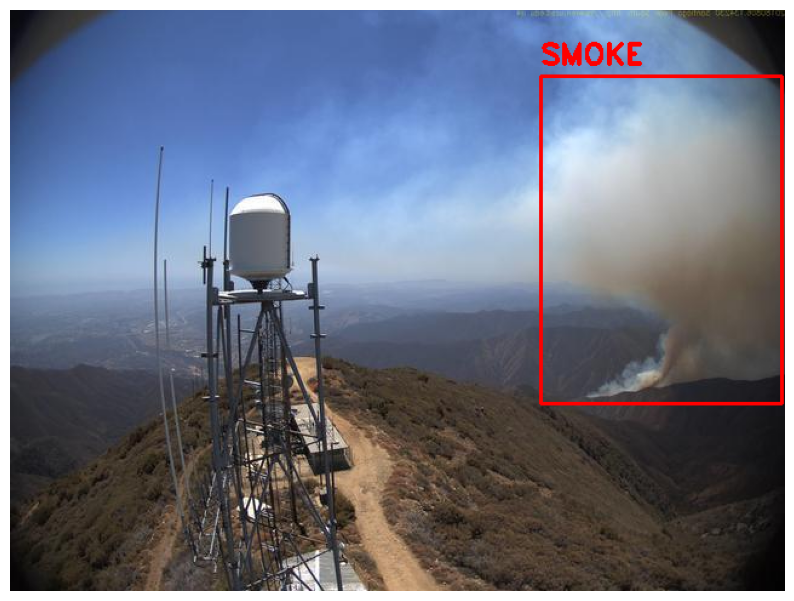

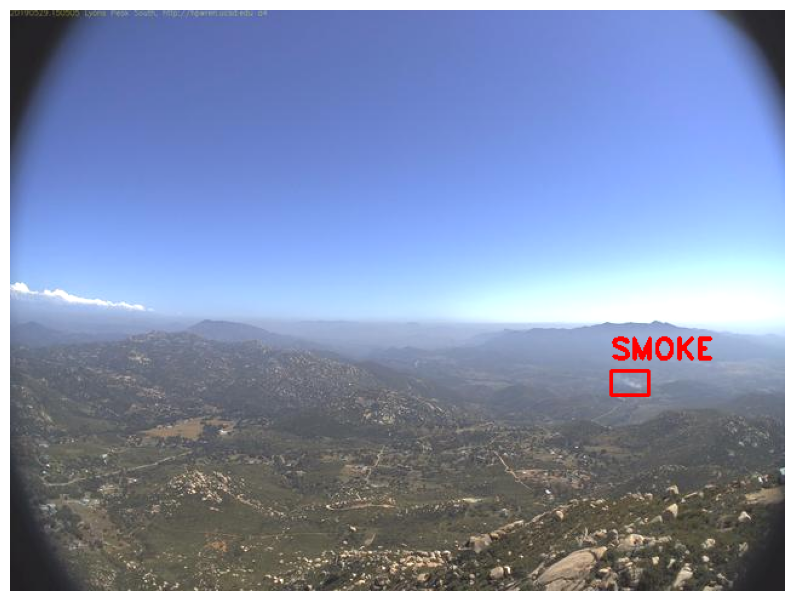

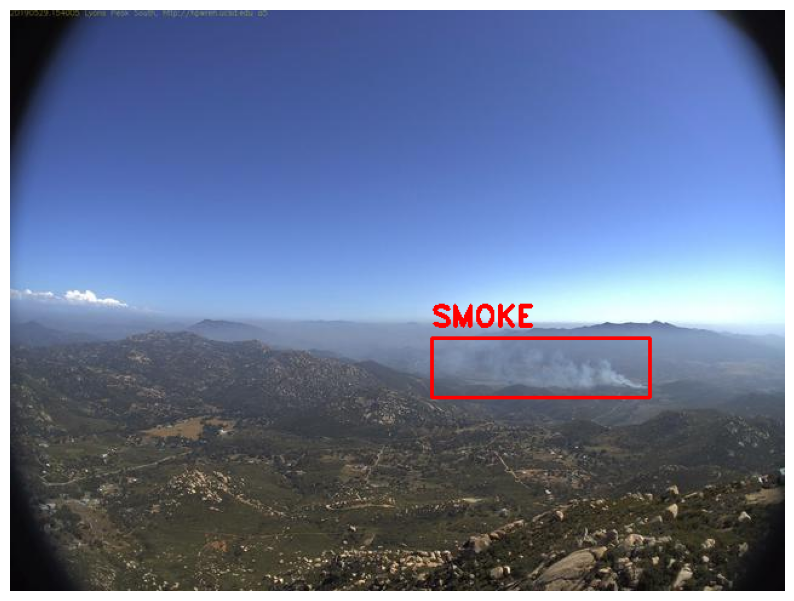

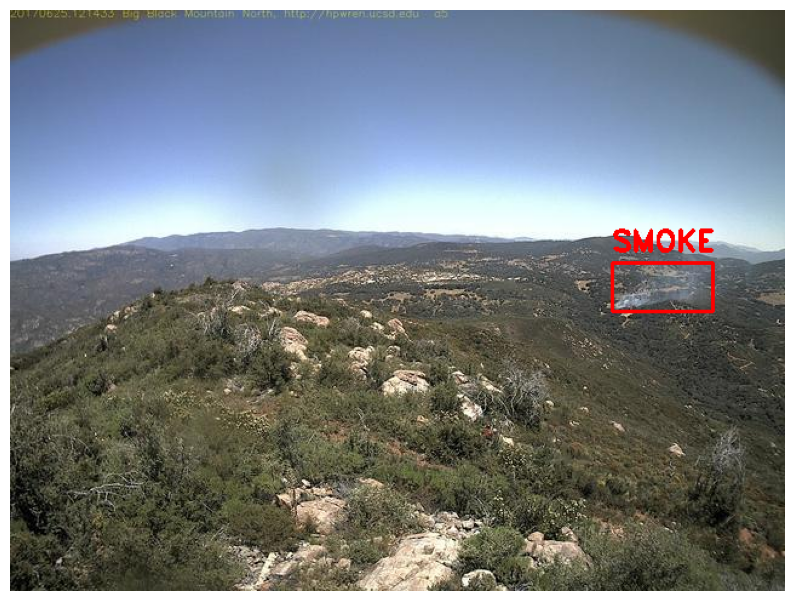

In [ ]:
# Train set - images and boxes
images, targets = next(iter(data_loader_train))
plot_images(images, targets)

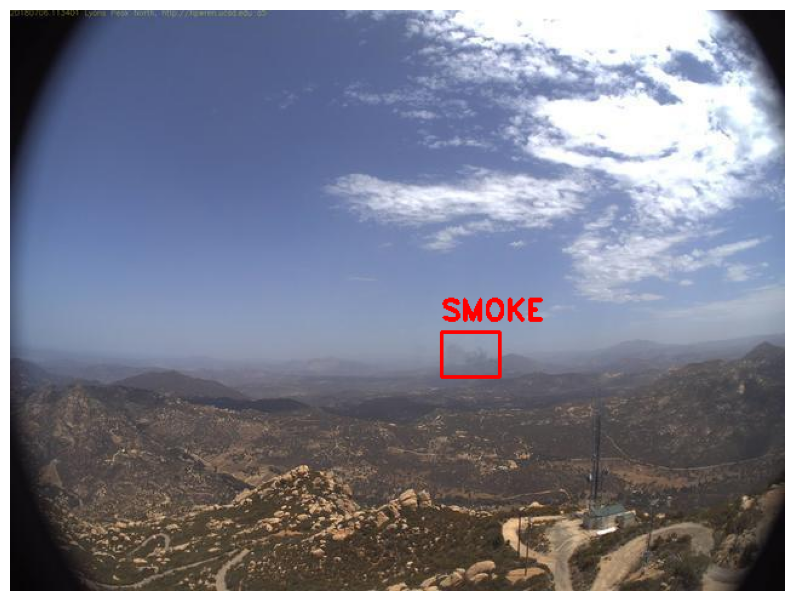

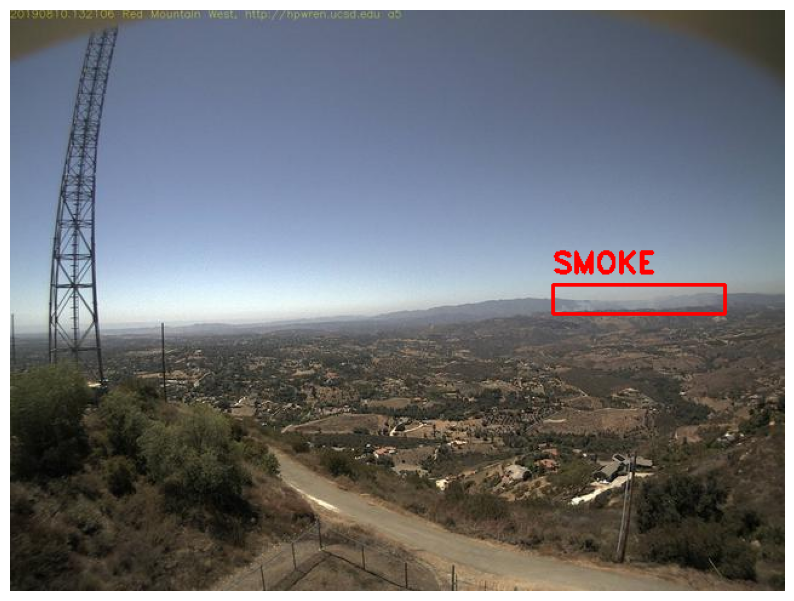

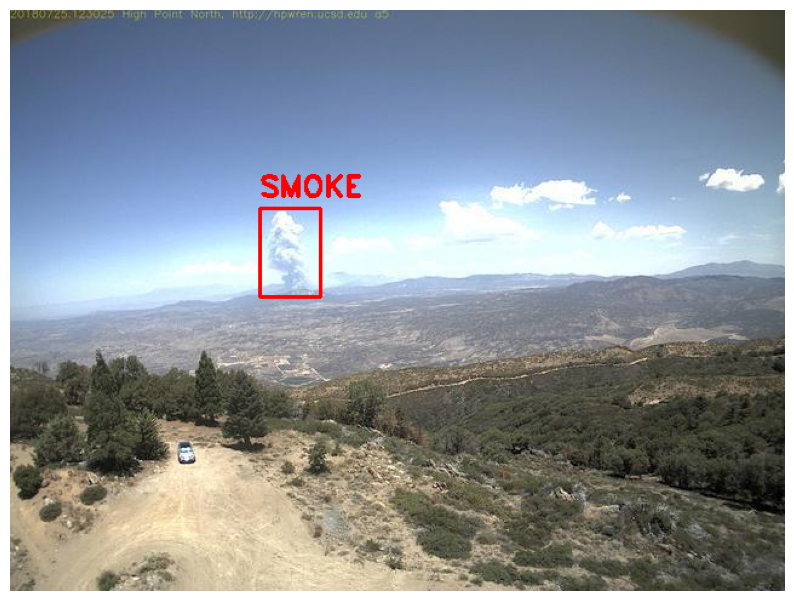

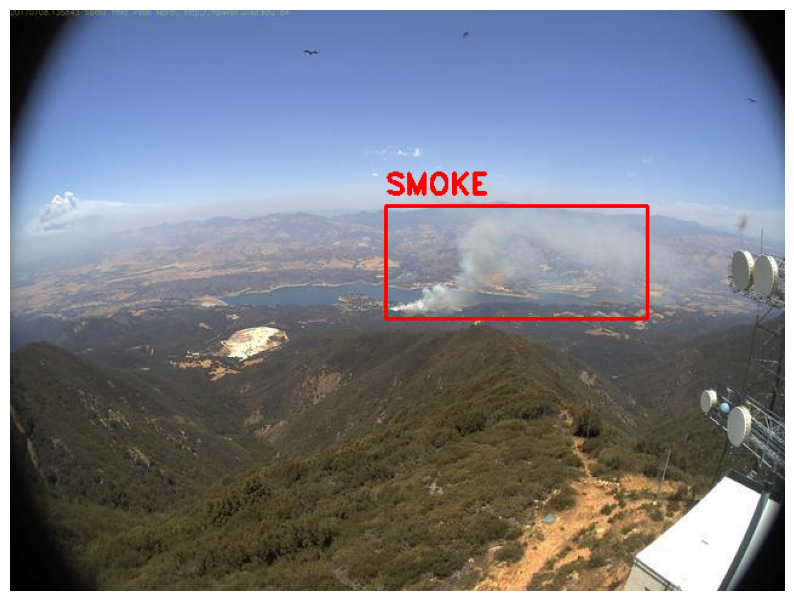

In [ ]:
# Validation set - images and boxes
images, targets = next(iter(data_loader_valid))
plot_images(images, targets)

##Model & Dataset

### Import model pre-train

Available models, pre-trained on COCO dataset, at https://pytorch.org/vision/master/models/faster_rcnn.html.



In [ ]:
import torchvision
# Transfer learning: load a model pre-trained on COCO
detection_model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
100%|██████████| 160M/160M [00:01<00:00, 89.4MB/s]


In [ ]:
num_classes = 2

# Get the number of input features for the classifier
in_features = detection_model.roi_heads.box_predictor.cls_score.in_features

# Replace the pre-trained head with a new one
detection_model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, num_classes)

In [ ]:
detection_model = detection_model.to(device)

In [ ]:
from engine import train_one_epoch, evaluate
def training(model, train_loader, val_loader, epochs):

    # Optimizer and learning rate
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

    # Adapter
    lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

    for epoch in range(epochs):

        # Train for one epoch, printing every 'print_freq'
        train_one_epoch(model, optimizer, train_loader, device, epoch, print_freq=len(data_loader_train))

        # Update the learning rate
        lr_scheduler.step()

        # Evaluate on the validation set
        evaluate(model, val_loader, device=device)

training(detection_model, data_loader_train, data_loader_valid, epochs=20)

Epoch: [0]  [  0/129]  eta: 0:07:16  lr: 0.000044  loss: 0.6764 (0.6764)  loss_classifier: 0.3909 (0.3909)  loss_box_reg: 0.0511 (0.0511)  loss_objectness: 0.2175 (0.2175)  loss_rpn_box_reg: 0.0168 (0.0168)  time: 3.3817  data: 0.2240  max mem: 4013
Epoch: [0]  [128/129]  eta: 0:00:01  lr: 0.005000  loss: 0.1422 (0.2154)  loss_classifier: 0.0468 (0.0828)  loss_box_reg: 0.0876 (0.0946)  loss_objectness: 0.0043 (0.0313)  loss_rpn_box_reg: 0.0044 (0.0068)  time: 1.0610  data: 0.0182  max mem: 4174
Epoch: [0] Total time: 0:02:18 (1.0745 s / it)
creating index...
index created!
Test:  [ 0/37]  eta: 0:00:25  model_time: 0.4866 (0.4866)  evaluator_time: 0.0071 (0.0071)  time: 0.7009  data: 0.1967  max mem: 4174
Test:  [36/37]  eta: 0:00:00  model_time: 0.4634 (0.4590)  evaluator_time: 0.0036 (0.0040)  time: 0.4830  data: 0.0153  max mem: 4174
Test: Total time: 0:00:18 (0.4924 s / it)
Averaged stats: model_time: 0.4634 (0.4590)  evaluator_time: 0.0036 (0.0040)
Accumulating evaluation results..

In [ ]:
# ======================================
#   SAVE THE MODEL
# ======================================

# Save the model
torch.save(detection_model.state_dict(), '/content/drive/MyDrive/Wildfire Smoke Detection/detection_model.pt')

Predection

In [ ]:
# Load the model
detection_model.load_state_dict(torch.load('/content/drive/MyDrive/Wildfire Smoke Detection/detection_model.pt'))

<All keys matched successfully>

In [ ]:
test_path = '/content/dataset/test'

# Validation set transformations
transform_test = A.Compose([
    ToTensorV2(p=1)], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels']))

test_dataset = WildFireSmoke_Dataset(image_path=test_path, categories=['smoke'], transforms=transform_test)

data_loader_test = torch.utils.data.DataLoader(
        test_dataset,
        batch_size  = 4,
        shuffle     = True,
        num_workers = 2,
        collate_fn  = collate_fn)


In [ ]:
def view_sample(loader, model, device, threshold):

    images, targets = next(iter(loader))
    images = list(img.to(device) for img in images)
    targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

    boxes_gt = targets[0]['boxes'].cpu().numpy().astype(np.int32)
    sample = images[0].permute(1,2,0).cpu().numpy()

    model.to(device)
    model.eval()
    cpu_device = torch.device('cpu')

    outputs = model(images)
    outputs = [{k: v.to(cpu_device) for k, v in t.items()} for t in outputs]

    fig, ax = plt.subplots(1, 1, figsize=(16, 8))

    # Paint ground_truth boxes (red)
    for box in boxes_gt:
        color_red = (1,0,0)
        cv2.rectangle(sample,
              (box[0], box[1]),
              (box[2], box[3]),
              color_red, 2)

    boxes = outputs[0]['boxes'].data.cpu().numpy().astype(np.int32)
    scores = outputs[0]['scores'].data.cpu().numpy()

    pred_box_count = 0
    for box, p in zip(boxes, scores):
        if p > threshold:
            pred_box_count += 1
            color_blue = (0,0,1)
            cv2.rectangle(sample,
                  (box[0], box[1]),
                  (box[2], box[3]),
                  color_blue, 2)

    print(f'Predicted {pred_box_count} BBoxes (blue); Number of GT BBoxes (red) : {len(boxes_gt)}')
    ax.set_axis_off()
    ax.imshow((sample * 255).astype(np.uint8))

Predicted 1 BBoxes (blue); Number of GT BBoxes (red) : 1
Predicted 1 BBoxes (blue); Number of GT BBoxes (red) : 1
Predicted 1 BBoxes (blue); Number of GT BBoxes (red) : 1
Predicted 1 BBoxes (blue); Number of GT BBoxes (red) : 1
Predicted 1 BBoxes (blue); Number of GT BBoxes (red) : 1
Predicted 1 BBoxes (blue); Number of GT BBoxes (red) : 1
Predicted 1 BBoxes (blue); Number of GT BBoxes (red) : 1
Predicted 1 BBoxes (blue); Number of GT BBoxes (red) : 1
Predicted 2 BBoxes (blue); Number of GT BBoxes (red) : 1
Predicted 1 BBoxes (blue); Number of GT BBoxes (red) : 1


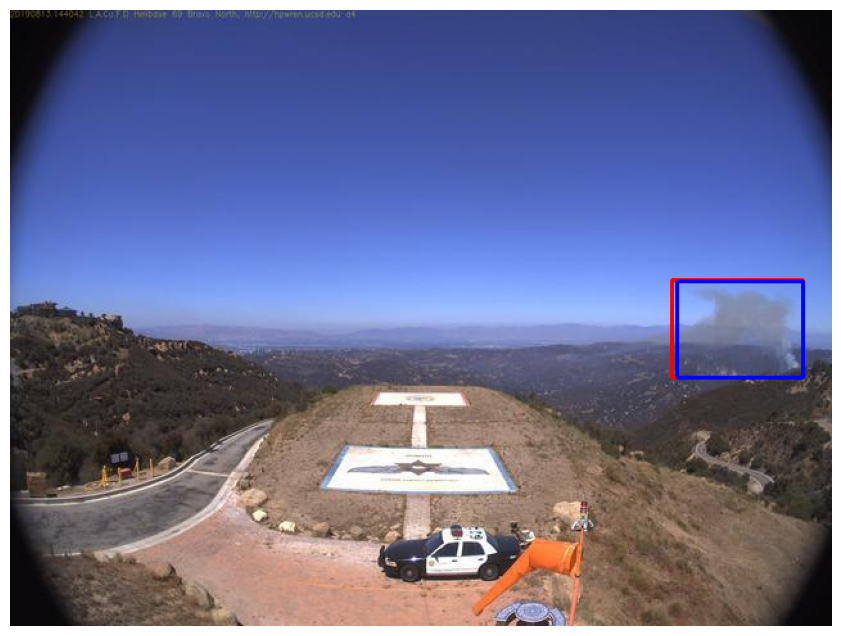

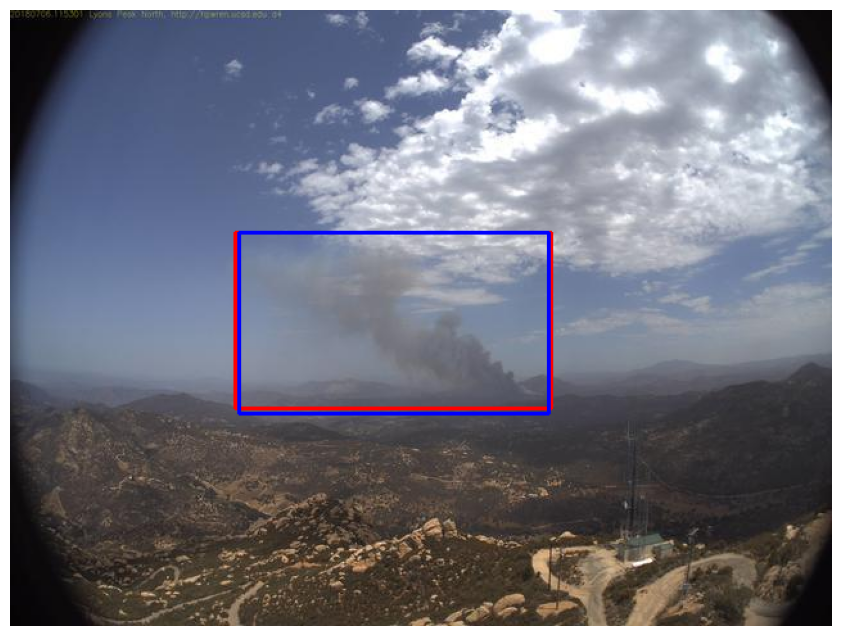

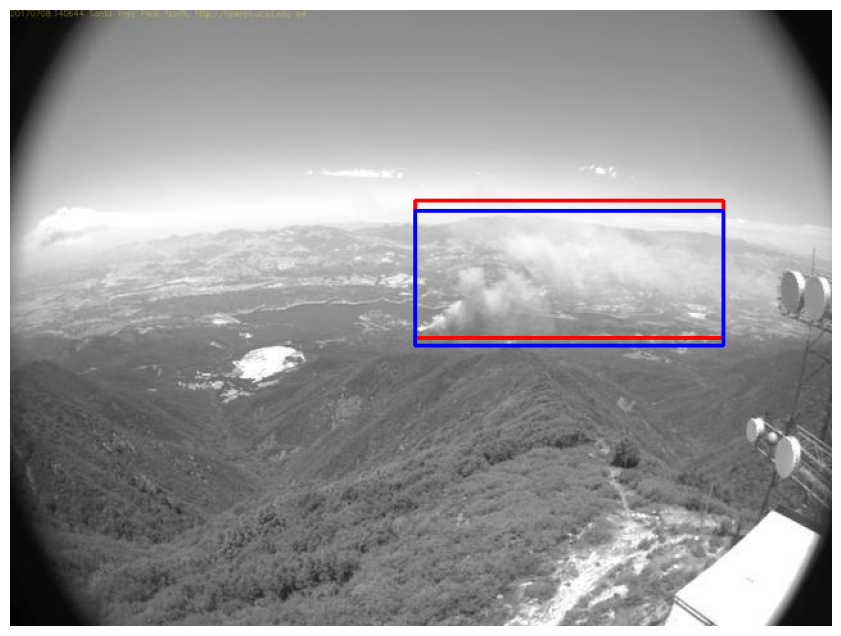

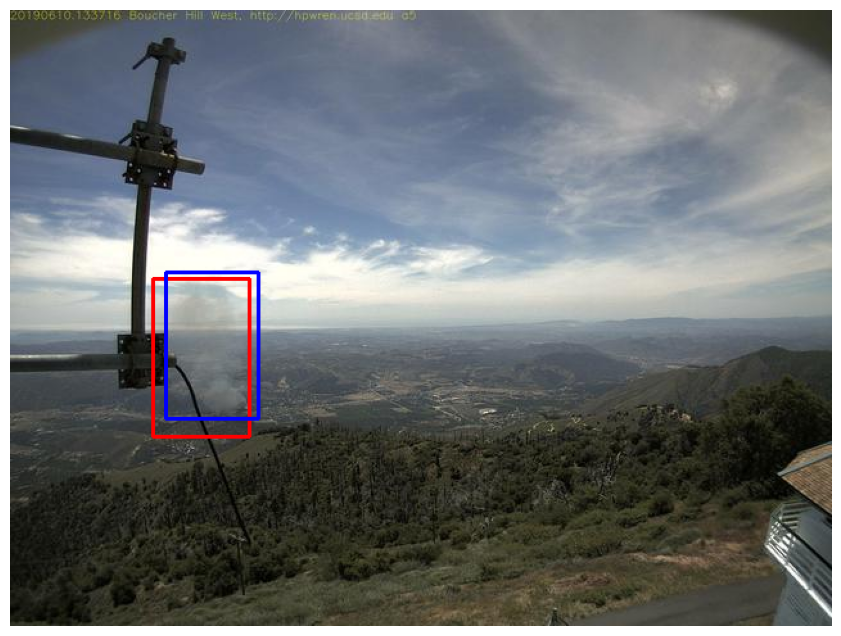

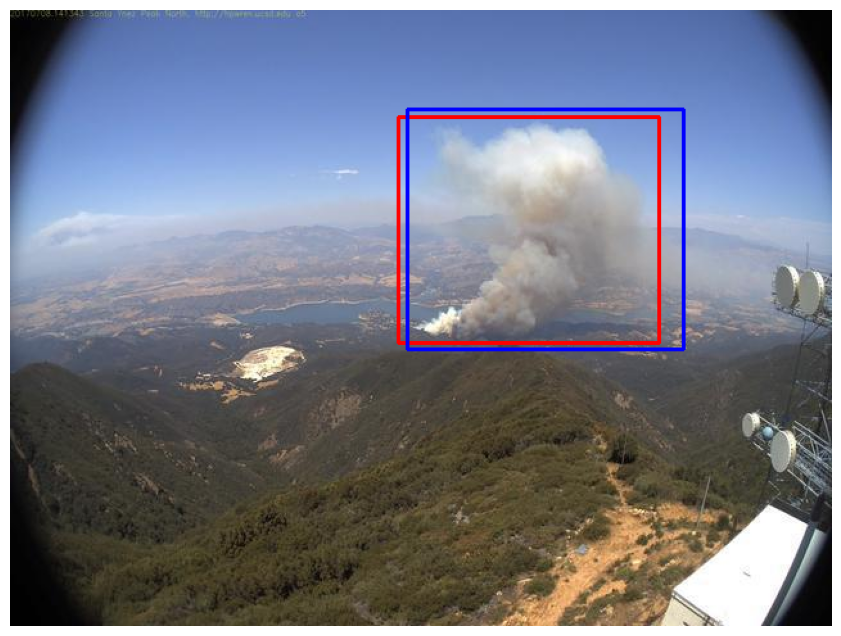

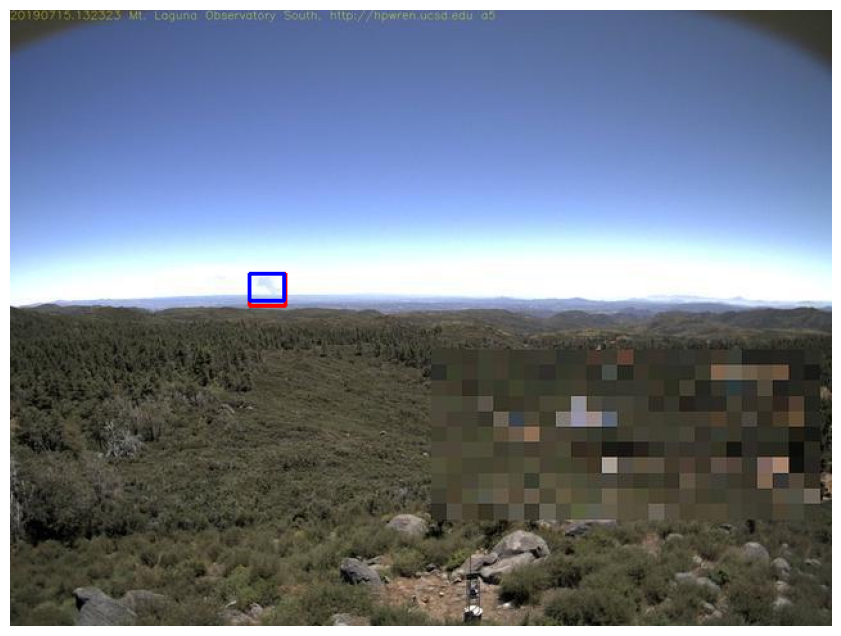

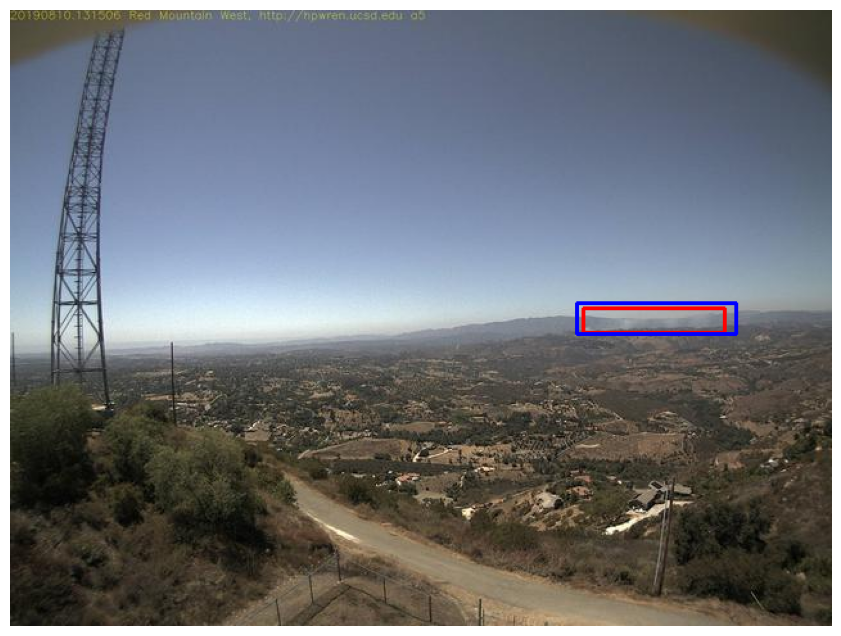

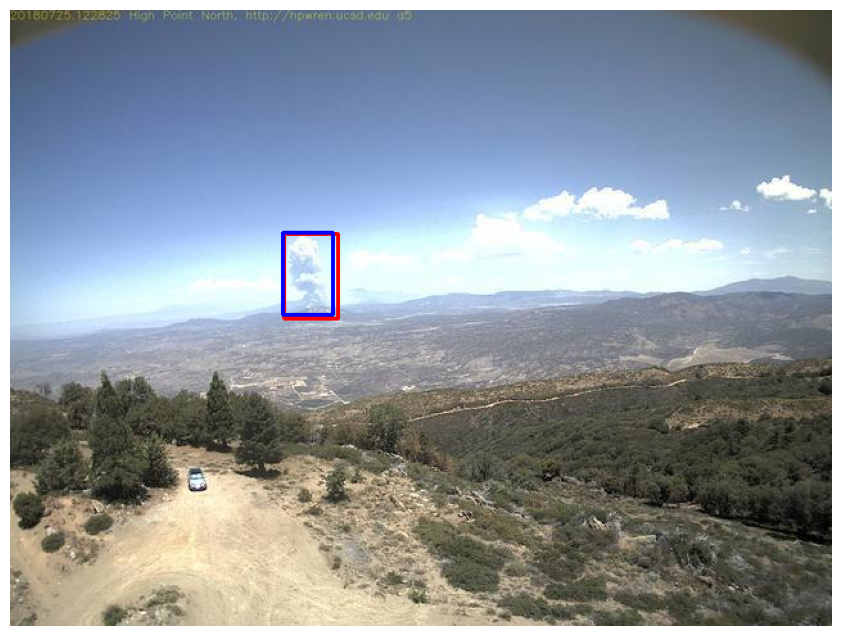

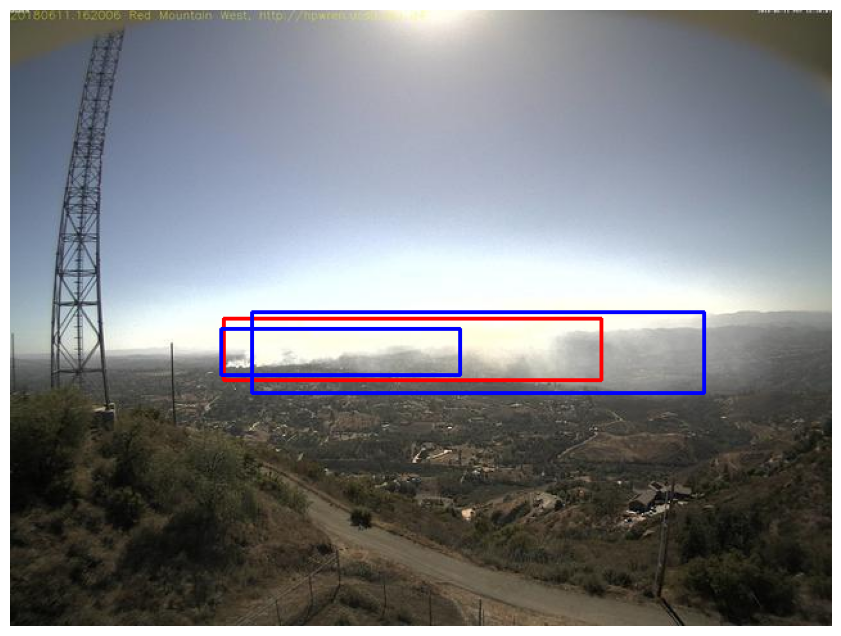

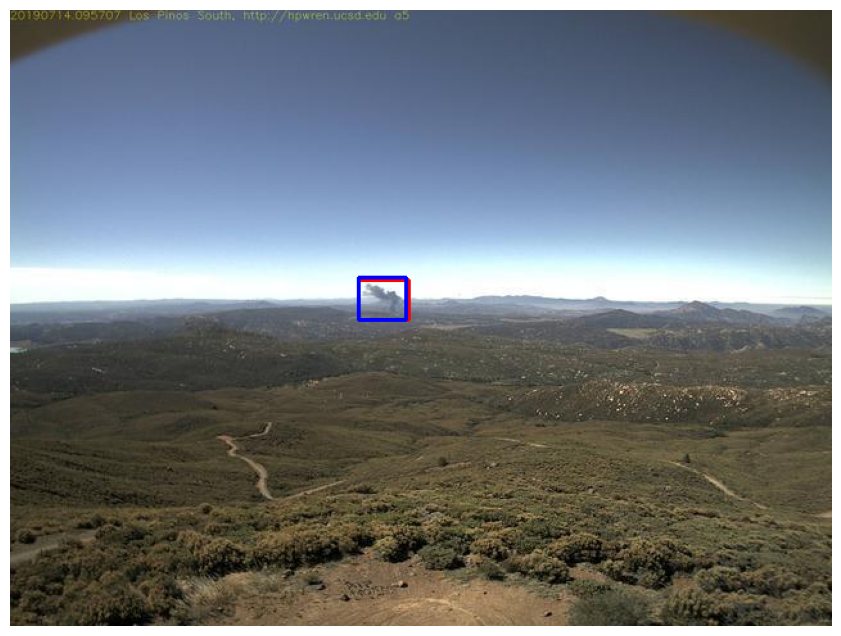

In [ ]:
for i in range(10):
    view_sample(data_loader_test, detection_model, device, 0.6)